# _**Exploratory Data Analysis of Concrete Defect Point Clouds**_

> This notebook presents the initial exploration of the concrete point-cloud dataset used in this research. The aim is to understand the dataset structure, examine the available point-cloud files, and assess the quality and characteristics of the data before implementing the PointNet-based models.

>The analysis will cover file inspection, point distribution, coordinate ranges, data consistency, and visualisation of selected point-cloud segments

In [1]:
# importing libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
# data directory
data_dir = Path('../data/SNEPointNet2/data')

# Get all point-cloud text files
point_files = sorted(data_dir.glob("*.txt"))

# Display the results
print("Dataset directory:", data_dir.resolve())
print("Total number of point-cloud files:", len(point_files))

print("\nFirst five files:")
for file in point_files[:5]:
    print(file.name)

Dataset directory: /mnt/c/Users/Danhaya/ArewaDS/pointnet-concrete-defect-robustness/data/SNEPointNet2/data
Total number of point-cloud files: 102

First five files:
part (1).txt
part (10).txt
part (100).txt
part (101).txt
part (102).txt


Let me examines a sample point-cloud file to understand its structure and numerical format. This may helps in the future analysis.

In [3]:
# first point-cloud file
sample_file = point_files[0]

# Display its name and size
print("Selected file:", sample_file.name)
print("File size:", round(sample_file.stat().st_size / 1024, 2), "KB")

# Read and display the first five lines
with open(sample_file, "r") as file:
    for i in range(5):
        print(file.readline().strip())

Selected file: part (1).txt
File size: 22499.25 KB
28.755 6.229 10.433 132 117 76 0.008867 -0.999960 -0.000985
28.754 6.229 10.519 138 126 88 0.008884 -0.999956 -0.002961
28.736 6.229 10.544 136 123 91 0.004907 -0.999987 0.000981
28.754 6.229 10.474 128 110 70 0.012857 -0.999917 0.000989
28.754 6.229 10.412 136 122 87 0.002944 -0.999995 -0.000981


In [4]:
# Load one point-cloud file
point_cloud = np.loadtxt(sample_file)

# Display basic information
print("Data shape:", point_cloud.shape)
print("Data type:", point_cloud.dtype)

print("\nFirst five points:")
print(point_cloud[:5])

Data shape: (384346, 9)
Data type: float64

First five points:
[[ 2.87550e+01  6.22900e+00  1.04330e+01  1.32000e+02  1.17000e+02
   7.60000e+01  8.86700e-03 -9.99960e-01 -9.85000e-04]
 [ 2.87540e+01  6.22900e+00  1.05190e+01  1.38000e+02  1.26000e+02
   8.80000e+01  8.88400e-03 -9.99956e-01 -2.96100e-03]
 [ 2.87360e+01  6.22900e+00  1.05440e+01  1.36000e+02  1.23000e+02
   9.10000e+01  4.90700e-03 -9.99987e-01  9.81000e-04]
 [ 2.87540e+01  6.22900e+00  1.04740e+01  1.28000e+02  1.10000e+02
   7.00000e+01  1.28570e-02 -9.99917e-01  9.89000e-04]
 [ 2.87540e+01  6.22900e+00  1.04120e+01  1.36000e+02  1.22000e+02
   8.70000e+01  2.94400e-03 -9.99995e-01 -9.81000e-04]]


_The sample file contains 384,346 points, with nine numerical features per point. These features appear to represent 3D coordinates, RGB colour values, and surface normal components. The data was successfully loaded into NumPy as a two-dimensional array of type `float64`._

This step examines the number of points contained in each point-cloud file. Comparing the files will help us understand variations in dataset size and determine whether the point clouds have consistent sampling characteristics.

In [5]:
# Count the number of points in each file
point_counts = []

for file in point_files:
    with open(file, "r") as f:
        count = sum(1 for line in f if line.strip())

    point_counts.append({
        "file": file.name,
        "number_of_points": count
    })

# Convert the results into a DataFrame
point_distribution = pd.DataFrame(point_counts)

# Display the first five results
point_distribution.head()

,file,number_of_points
0,part (1).txt,384346
1,part (10).txt,346994
2,part (100).txt,380314
3,part (101).txt,423704
4,part (102).txt,342697


This variation indicates differences in the number of spatial measurements recorded for each concrete segment, which may influence point-cloud sampling and model input preparation.

In [6]:
# Calculate descriptive statistics for point counts
point_distribution["number_of_points"].describe()

count       102.000000
mean     261747.931373
std       96566.489757
min       79719.000000
25%      189460.750000
50%      260242.500000
75%      337164.750000
max      500720.000000
Name: number_of_points, dtype: float64

_The dataset contains 102 point-cloud files, with an average of approximately 261,748 points per file. The point counts range from 79,719 to 500,720, indicating considerable variation in the size of the point clouds. The mean and median are relatively close, suggesting a reasonably centred distribution. These variations are important when preparing the dataset for PointNet, as a consistent number of input points may be required during model training_.

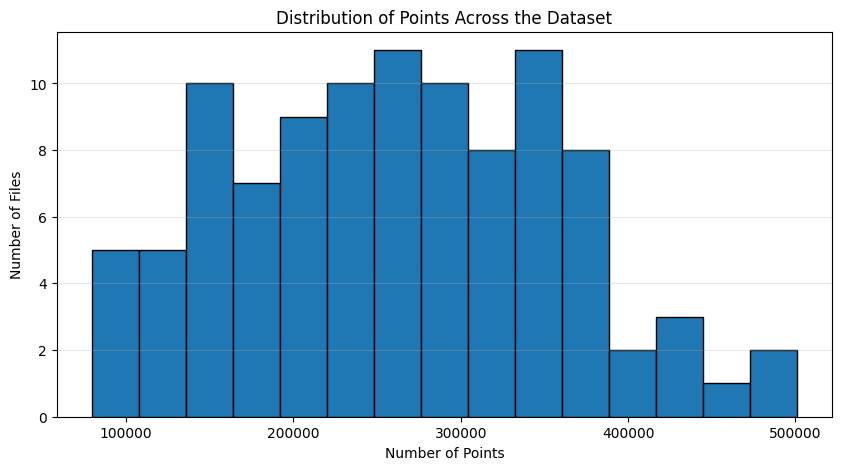

In [7]:

plt.figure(figsize=(10, 5))

plt.hist(
    point_distribution["number_of_points"],
    bins=15,
    edgecolor="black"
)

plt.xlabel("Number of Points")
plt.ylabel("Number of Files")
plt.title("Distribution of Points Across the Dataset")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [8]:
# Calculate descriptive statistics for all nine attributes
attribute_summary = pd.DataFrame({
    "Minimum": np.min(point_cloud, axis=0),
    "Maximum": np.max(point_cloud, axis=0),
    "Mean": np.mean(point_cloud, axis=0),
    "Standard Deviation": np.std(point_cloud, axis=0)
}, index=[
    "X", "Y", "Z",
    "Red", "Green", "Blue",
    "Normal_X", "Normal_Y", "Normal_Z"
])

attribute_summary

,Minimum,Maximum,Mean,Standard Deviation
X,26.075000,29.161000,27.608900,0.899278
Y,6.157000,6.236000,6.217785,0.007855
Z,7.966000,10.816000,9.379767,0.819457
Red,26.000000,255.000000,166.484129,28.148254
Green,26.000000,236.000000,150.218139,25.389937
Blue,19.000000,215.000000,124.396398,27.467708
Normal_X,-0.999999,0.999852,-0.019787,0.124392
Normal_Y,-0.999999,0.999948,-0.947110,0.291970
Normal_Z,-0.990232,0.975427,0.001618,0.043237


_The point-cloud file contains nine attributes per point: three spatial coordinates (X, Y, Z), three RGB colour components, and three surface normal components. The spatial coordinates describe the 3D positions of points, while the RGB values provide information about surface appearance. The surface normals represent the local geometric orientation of the concrete surface. These combined attributes provide spatial, colour, and geometric information for subsequent semantic segmentation._

In [9]:
# Extract the three surface normal components
normal_vectors = point_cloud[:, 6:9]

# Calculate the magnitude of each normal vector
normal_magnitudes = np.linalg.norm(normal_vectors, axis=1)

# Summarise the normal magnitudes
print("Normal vector magnitude statistics:")
print(pd.Series(normal_magnitudes).describe())

# Check the proportion of approximately unit-length normals
unit_normals = np.isclose(normal_magnitudes, 1.0, atol=0.01)

print("\nPercentage of approximately unit-length normals:",
      round(unit_normals.mean() * 100, 2), "%")

Normal vector magnitude statistics:
count    3.843460e+05
mean     1.000000e+00
std      2.935459e-07
min      9.999992e-01
25%      9.999997e-01
50%      1.000000e+00
75%      1.000000e+00
max      1.000001e+00
dtype: float64

Percentage of approximately unit-length normals: 100.0 %


_The magnitude of the surface normal vectors was calculated to verify their normalization. The results show a mean magnitude of 1.000000, with minimum and maximum values of 0.9999992 and 1.000001, respectively. This confirms that the surface normal vectors are already normalized to approximately unit length._ 

In [10]:
# Inspect the structure of every point-cloud file
file_structure = []

for file in point_files:
    try:
        cloud = np.loadtxt(file, ndmin=2)

        file_structure.append({
            "file": file.name,
            "number_of_points": cloud.shape[0],
            "number_of_attributes": cloud.shape[1],
            "data_type": str(cloud.dtype),
            "status": "Valid"
        })

    except (ValueError, OSError) as error:
        file_structure.append({
            "file": file.name,
            "number_of_points": None,
            "number_of_attributes": None,
            "data_type": None,
            "status": str(error)
        })

# Convert results into a DataFrame
file_structure_df = pd.DataFrame(file_structure)

# Display the first five results
file_structure_df.head()

,file,number_of_points,number_of_attributes,data_type,status
0,part (1).txt,384346,9,float64,Valid
1,part (10).txt,346994,9,float64,Valid
2,part (100).txt,380314,9,float64,Valid
3,part (101).txt,423704,9,float64,Valid
4,part (102).txt,342697,9,float64,Valid


In [11]:
# Examine the consistency of attributes and data types
print("Number of files examined:", len(file_structure_df))

print("\nAttribute counts:")
print(file_structure_df["number_of_attributes"].value_counts(dropna=False))

print("\nData types:")
print(file_structure_df["data_type"].value_counts(dropna=False))

print("\nFile status:")
print(file_structure_df["status"].value_counts())

Number of files examined: 102

Attribute counts:
number_of_attributes
9    102
Name: count, dtype: int64

Data types:
data_type
float64    102
Name: count, dtype: int64

File status:
status
Valid    102
Name: count, dtype: int64


_All 102 point-cloud files contain nine attributes per point and are consistently stored as float64 numerical arrays. No file-reading errors or structural inconsistencies were identified, although the number of points varies across files._

### `Data Quality Assessment`

In [12]:
# Check for missing and infinite values
quality_results = []

for file in point_files:
    cloud = np.loadtxt(file)

    quality_results.append({
        "file": file.name,
        "missing_values": np.isnan(cloud).sum(),
        "infinite_values": np.isinf(cloud).sum()
    })

# Convert results into a DataFrame
quality_df = pd.DataFrame(quality_results)

# Display the summary
quality_df[["missing_values", "infinite_values"]].sum()

missing_values     0
infinite_values    0
dtype: int64

_All 102 point-cloud files were examined for missing and infinite numerical values, with no occurrences detected. This indicates that the dataset contains complete and finite numerical entries for subsequent data processing_.

In [13]:
# Check for duplicate 3D coordinates in each file
duplicate_results = []

for file in point_files:
    cloud = np.loadtxt(file)

    coordinates = cloud[:, :3]

    duplicate_count = (
        len(coordinates) - len(np.unique(coordinates, axis=0))
    )

    duplicate_results.append({
        "file": file.name,
        "duplicate_points": duplicate_count
    })

# Convert results into a DataFrame
duplicate_df = pd.DataFrame(duplicate_results)

# Display total duplicate points
print("Total duplicate 3D coordinates:",
      duplicate_df["duplicate_points"].sum())

Total duplicate 3D coordinates: 329672


In [14]:
# Display files with the highest number of duplicate coordinates
duplicate_df.sort_values(
    by="duplicate_points",
    ascending=False
).head(10)

,file,duplicate_points
89,part (88).txt,108207
41,part (44).txt,32096
28,part (32).txt,29137
62,part (63).txt,22550
64,part (65).txt,22458
48,part (50).txt,19852
2,part (100).txt,16708
44,part (47).txt,14565
11,part (17).txt,11262
67,part (68).txt,10045


In [15]:
# Load the file with the highest duplicate count
sample_duplicate_cloud = np.loadtxt(data_dir / "part (88).txt")

# Identify unique and repeated XYZ coordinates
coordinates = sample_duplicate_cloud[:, :3]

unique_coordinates, inverse, counts = np.unique(
    coordinates,
    axis=0,
    return_inverse=True,
    return_counts=True
)

# Find coordinates that occur more than once
duplicate_indices = np.where(counts > 1)[0]

# Display the number of repeated coordinate groups
print("Repeated coordinate groups:", len(duplicate_indices))

print("Total points belonging to repeated groups:",
      counts[duplicate_indices].sum())

# Extract all nine attributes for repeated coordinate groups
repeated_points = sample_duplicate_cloud[
    np.isin(inverse, duplicate_indices)
]

# Count unique complete records among repeated points
unique_full_records = np.unique(repeated_points, axis=0)

# Display the results
print("Points in repeated coordinate groups:", len(repeated_points))

print("Unique complete records:", len(unique_full_records))

print("Repeated complete records:",
      len(repeated_points) - len(unique_full_records))

Repeated coordinate groups: 91469
Total points belonging to repeated groups: 199676
Points in repeated coordinate groups: 199676
Unique complete records: 199534
Repeated complete records: 142


In [16]:
# Find the first repeated XYZ coordinate
first_duplicate_group = duplicate_indices[0]

# Retrieve all points sharing that coordinate
example_points = sample_duplicate_cloud[
    inverse == first_duplicate_group
]

# Display the repeated points
print("Repeated XYZ coordinate:")
print(example_points[:, :3])

print("\nCorresponding RGB and normal attributes:")
print(example_points[:, 3:])

Repeated XYZ coordinate:
[[ -0.378  -3.484 -84.856]
 [ -0.378  -3.484 -84.856]]

Corresponding RGB and normal attributes:
[[ 1.66000e+02  1.43000e+02  1.25000e+02  9.78000e-04  9.99999e-01
  -9.78000e-04]
 [ 1.82000e+02  1.61000e+02  1.40000e+02 -9.78000e-04  9.99999e-01
  -9.78000e-04]]


In [17]:
# Examine the frequency of repeated coordinates
duplicate_frequency = pd.Series(counts[duplicate_indices])

print("Maximum repetitions at one coordinate:",
      duplicate_frequency.max())

print("\nFrequency distribution:")
print(duplicate_frequency.value_counts().sort_index())

Maximum repetitions at one coordinate: 8

Frequency distribution:
2    79298
3     7618
4     4547
5        2
6        2
8        2
Name: count, dtype: int64


The analysis revealed 91,469 repeated XYZ coordinate groups in part (88).txt, with most locations occurring twice and a maximum repetition of eight. Most repeated spatial locations have different RGB or surface-normal attributes, indicating that spatial duplication does not necessarily represent exact duplicate records.

In [18]:
# Analyse duplicate XYZ coordinates across all files
duplicate_analysis = []

for file in point_files:
    cloud = np.loadtxt(file)
    coordinates = cloud[:, :3]

    _, coordinate_counts = np.unique(
        coordinates,
        axis=0,
        return_counts=True
    )

    repeated_groups = coordinate_counts[coordinate_counts > 1]

    duplicate_analysis.append({
        "file": file.name,
        "repeated_groups": len(repeated_groups),
        "points_in_repeated_groups": repeated_groups.sum(),
        "maximum_repetitions": (
            repeated_groups.max() if len(repeated_groups) > 0 else 0
        )
    })

# Create a DataFrame
duplicate_analysis_df = pd.DataFrame(duplicate_analysis)

# Display summary statistics
duplicate_analysis_df.describe()

,repeated_groups,points_in_repeated_groups,maximum_repetitions
count,102.000000,102.000000,102.000000
mean,2981.607843,6213.686275,1.107843
std,10564.327957,22700.175406,1.488616
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,142.000000,284.000000,2.000000
max,91469.000000,199676.000000,8.000000


_The analysis revealed substantial variation in duplicate XYZ coordinates across the 102 point-cloud files, with a median of zero repeated groups and a maximum of 91,469. This indicates that spatial duplication is concentrated in a small number of files rather than being uniformly distributed throughout the dataset_.

In [19]:
# Calculate the percentage of points in repeated-coordinate groups
duplicate_analysis_df = duplicate_analysis_df.merge(
    point_distribution,
    on="file"
)

duplicate_analysis_df["duplicate_percentage"] = (
    duplicate_analysis_df["points_in_repeated_groups"] /
    duplicate_analysis_df["number_of_points"] * 100
)

# Display the 10 files with the highest duplicate percentages
duplicate_analysis_df.sort_values(
    by="duplicate_percentage",
    ascending=False
)[[
    "file",
    "number_of_points",
    "points_in_repeated_groups",
    "duplicate_percentage"
]].head(10)

,file,number_of_points,points_in_repeated_groups,duplicate_percentage
89,part (88).txt,464239,199676,43.011466
67,part (68).txt,93989,20090,21.374842
41,part (44).txt,320909,60760,18.933716
62,part (63).txt,274342,45004,16.404342
64,part (65).txt,338592,43133,12.738931
44,part (47).txt,230424,29130,12.641912
28,part (32).txt,486062,56828,11.691513
48,part (50).txt,344552,38445,11.157967
70,part (70).txt,182092,16936,9.300793
2,part (100).txt,380314,32965,8.667838


In [20]:
# Calculate overall duplicate-coordinate percentage
total_points = point_distribution["number_of_points"].sum()

total_repeated_points = duplicate_analysis_df[
    "points_in_repeated_groups"
].sum()

overall_duplicate_percentage = (
    total_repeated_points / total_points
) * 100

print("Total points:", total_points)
print("Points in repeated-coordinate groups:", total_repeated_points)
print("Overall duplicate-coordinate percentage:",
      round(overall_duplicate_percentage, 2), "%")

Total points: 26698289
Points in repeated-coordinate groups: 633796
Overall duplicate-coordinate percentage: 2.37 %


Across the 102 point-cloud files, 633,796 points were identified as belonging to repeated XYZ coordinate groups, representing 2.37% of the 26.7 million points. Although duplication is relatively low at the dataset level, its concentration in specific files warrants further investigation before deciding whether any points should be removed.

In [21]:
# Examine coordinate ranges across all point-cloud files
coordinate_ranges = []

for file in point_files:
    cloud = np.loadtxt(file)

    coordinates = cloud[:, :3]

    coordinate_ranges.append({
        "file": file.name,
        "X_min": coordinates[:, 0].min(),
        "X_max": coordinates[:, 0].max(),
        "Y_min": coordinates[:, 1].min(),
        "Y_max": coordinates[:, 1].max(),
        "Z_min": coordinates[:, 2].min(),
        "Z_max": coordinates[:, 2].max()
    })

# Convert results into a DataFrame
coordinate_ranges_df = pd.DataFrame(coordinate_ranges)

# Display the first five files
coordinate_ranges_df.head()

,file,X_min,X_max,Y_min,Y_max,Z_min,Z_max
0,part (1).txt,26.075,29.161,6.157,6.236,7.966,10.816
1,part (10).txt,0.007,1.427,-1.195,-1.151,4.689,6.541
2,part (100).txt,-0.890,-0.237,1.836,1.864,11.583,12.551
3,part (101).txt,26.128,29.209,6.198,6.375,10.941,14.207
4,part (102).txt,26.155,29.108,12.660,12.739,11.262,14.197


_The spatial coordinate ranges vary considerably across the examined point-cloud files, indicating differences in their 3D spatial positions and extents. These variations require consideration during data preprocessing, particularly when determining appropriate coordinate normalization for PointNet._

In [22]:
# Calculate dataset-wide spatial coordinate statistics
coordinate_summary = []

for file in point_files:
    cloud = np.loadtxt(file)
    coordinates = cloud[:, :3]

    coordinate_summary.append(coordinates)

# Combine coordinates from all files
all_coordinates = np.vstack(coordinate_summary)

# Calculate descriptive statistics
coordinate_stats = pd.DataFrame({
    "Minimum": np.min(all_coordinates, axis=0),
    "Maximum": np.max(all_coordinates, axis=0),
    "Mean": np.mean(all_coordinates, axis=0),
    "Standard Deviation": np.std(all_coordinates, axis=0)
}, index=["X", "Y", "Z"])

coordinate_stats

,Minimum,Maximum,Mean,Standard Deviation
X,-20.296,30.093,10.669319,13.602264
Y,-14.471,26.896,5.277042,8.825274
Z,-86.112,54.342,-10.486404,42.619475


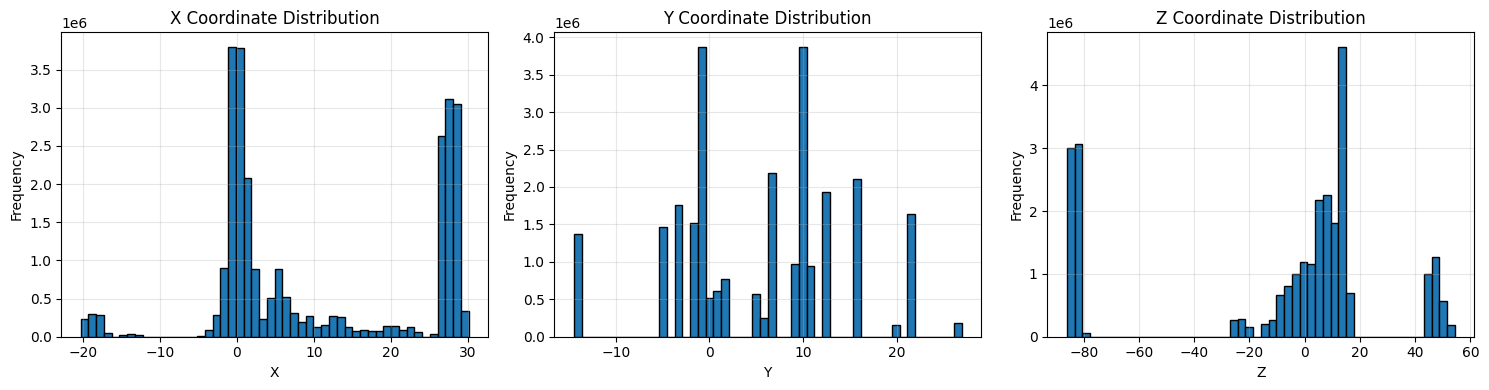

In [23]:
# Visualize spatial coordinate distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

coordinate_names = ["X", "Y", "Z"]

for i, ax in enumerate(axes):
    ax.hist(all_coordinates[:, i], bins=50, edgecolor="black")
    ax.set_title(f"{coordinate_names[i]} Coordinate Distribution")
    ax.set_xlabel(coordinate_names[i])
    ax.set_ylabel("Frequency")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

_The combined coordinate distributions exhibit multiple distinct peaks, indicating considerable spatial variation across the dataset. These patterns may reflect the different spatial positions of the point-cloud segments rather than data-quality problems_

In [24]:
coordinate_ranges_df["X_extent"] = (
    coordinate_ranges_df["X_max"] - coordinate_ranges_df["X_min"]
)

coordinate_ranges_df["Y_extent"] = (
    coordinate_ranges_df["Y_max"] - coordinate_ranges_df["Y_min"]
)

coordinate_ranges_df["Z_extent"] = (
    coordinate_ranges_df["Z_max"] - coordinate_ranges_df["Z_min"]
)

coordinate_ranges_df[
    ["file", "X_extent", "Y_extent", "Z_extent"]
].describe()

,X_extent,Y_extent,Z_extent
count,102.000000,102.000000,102.000000
mean,2.130127,0.054216,1.862314
std,0.935201,0.043883,0.808897
min,0.468000,0.010000,0.331000
25%,1.237250,0.028000,1.246000
50%,2.359000,0.038000,1.820000
75%,2.949750,0.066750,2.593750
max,4.998000,0.231000,3.266000


_The spatial extent analysis shows considerable variation in the dimensions of the 102 point-cloud segments, with X and Z having substantially larger extents than Y. The relatively small Y extent suggests that the scanned surfaces may be predominantly distributed along the X–Z plane_

In [25]:
for axis in ["X_extent", "Y_extent", "Z_extent"]:
    print(f"\nLargest {axis}:")
    print(
        coordinate_ranges_df.nlargest(5, axis)[
            ["file", axis]
        ]
    )

    print(f"\nSmallest {axis}:")
    print(
        coordinate_ranges_df.nsmallest(5, axis)[
            ["file", axis]
        ]
    )


Largest X_extent:
             file  X_extent
12  part (18).txt     4.998
58   part (6).txt     3.323
77  part (77).txt     3.304
78  part (78).txt     3.304
81  part (80).txt     3.273

Smallest X_extent:
              file  X_extent
89   part (88).txt     0.468
11   part (17).txt     0.552
67   part (68).txt     0.646
2   part (100).txt     0.653
40   part (43).txt     0.677

Largest Y_extent:
              file  Y_extent
22   part (27).txt     0.231
16   part (21).txt     0.191
15   part (20).txt     0.180
19   part (24).txt     0.180
3   part (101).txt     0.177

Smallest Y_extent:
              file  Y_extent
67   part (68).txt     0.010
49   part (51).txt     0.013
98   part (96).txt     0.013
55   part (57).txt     0.014
100  part (98).txt     0.014

Largest Z_extent:
              file  Z_extent
3   part (101).txt     3.266
54   part (56).txt     3.153
73   part (73).txt     3.132
25    part (3).txt     3.076
14    part (2).txt     3.057

Smallest Z_extent:
             file  

**`summary`**

_The data quality assessment showed that all 102 point-cloud files have consistent data structures, with no missing or infinite values. Repeated spatial coordinates were identified in some files, although most repeated locations do not represent identical complete records. The coordinate ranges and spatial extents also vary across the dataset, indicating differences in the spatial dimensions and positions of individual segments. These findings provide an initial understanding of the dataset quality and will inform subsequent preprocessing decisions._

# Statistical Analysis and Visualization
## Inspection of Dataset Annotations